# 14 — A vs B, animated

A small 2-D example, one design variable x and one heading psi, to show where each acquisition samples. A: straddle of f at each point (x, psi). B: straddle of the worst case max over psi of f at each design x, sampled at its likeliest worst psi. Same initial design (6 samples), 28 samples each. Saves `results/worst_case_animation.gif`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import ListedColormap
from mvlse import Continuous, DesignSpace, fit_surrogate, grid_candidates, run_lse

# One design variable x and one "heading" psi. The worst heading psi*(x) = 0.3 + 0.4 x moves with
# the design, and the worst case g(x) = max_psi f = 0.8 sin(5x) crosses tau four times.
TAU, KAPPA = 0.3, 1.96
space = DesignSpace({"x": Continuous(0.0, 1.0), "psi": Continuous(0.0, 1.0)})
f = lambda x, psi: 0.8 * np.sin(5 * x) - 1.2 * (psi - (0.3 + 0.4 * x)) ** 2
blackbox = lambda pts: [float(f(p["x"], p["psi"])) for p in pts]

N_INIT, N_MAX = 6, 34
cand = grid_candidates(space, 41)
common = dict(threshold=TAU, method="hs_dim", n_init_per_category=N_INIT, max_evaluations=N_MAX,
              stop_when_confident=False, flip_tolerance=-1.0, verbose=False, seed=2, candidates=cand)
runs = {"A: straddle": run_lse(space, blackbox, acquisition="straddle", **common),
        "B: worst-case straddle": run_lse(space, blackbox, acquisition="worst_case", environment="psi",
                                          n_environment=41, **common)}
for k, r in runs.items():
    print(k, r.n_evaluations, "samples")

A: straddle 34 samples
B: worst-case straddle 34 samples


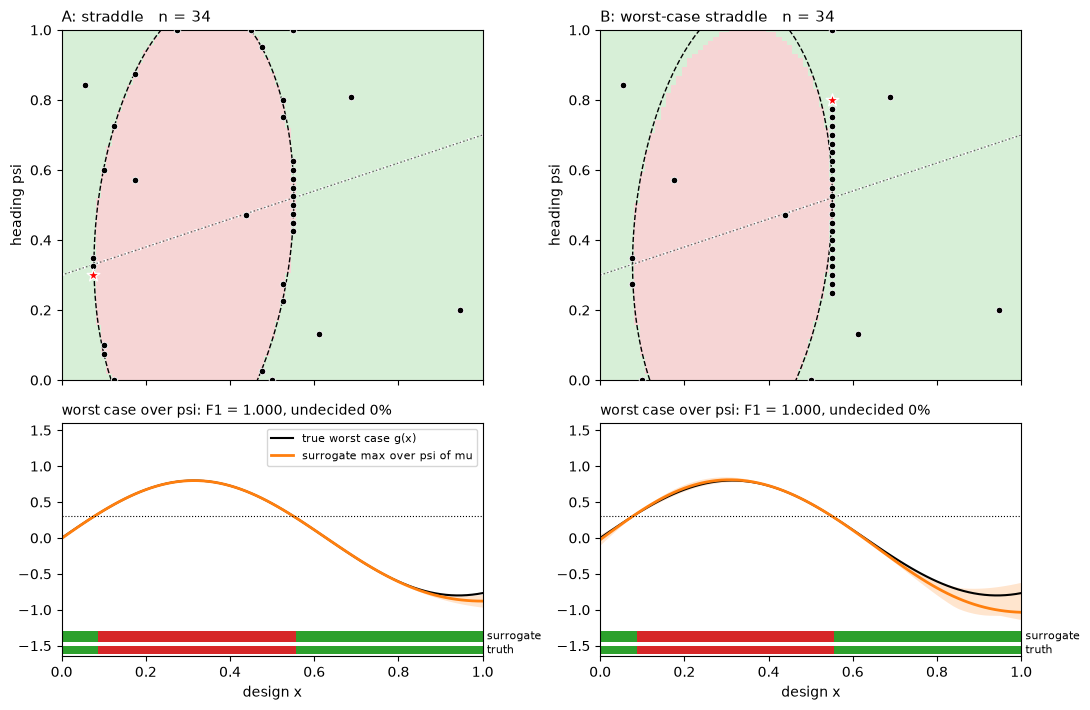

In [2]:
# One frame per sample. Top: the (x, psi) plane, pale green/red = surrogate mu <= / > tau, black
# dashed = true f = tau, white dotted = true worst heading, dots = samples (red = newest).
# Bottom: the worst case over psi: true g(x) (black), surrogate max_psi mu (orange) and the band
# [max (mu - k s), max (mu + k s)] that B scores; coloured strip = worst-case class from the
# surrogate (green safe, red unsafe, orange still undecided), ticks = truth.
G = 81
gx, gp = np.meshgrid(np.linspace(0, 1, G), np.linspace(0, 1, G), indexing="ij")
W = np.column_stack([gx.ravel(), gp.ravel()])
x_axis = gx[:, 0]
g_true = f(gx, gp).max(axis=1)
PALE = ListedColormap(["#d7efd7", "#f6d5d5"])
THREE = ListedColormap(["tab:green", "tab:orange", "tab:red"])

def state(r, n):
    m = fit_surrogate("hs_dim", space, r.w[:n], r.y[:n], rng=np.random.default_rng(0), n_starts=4)
    mu, sd = m.predict(W)
    mu, sd = mu.reshape(G, G), sd.reshape(G, G)
    U, L = (mu + KAPPA * sd).max(axis=1), (mu - KAPPA * sd).max(axis=1)
    cls = np.where(U <= TAU, 0, np.where(L > TAU, 2, 1))
    f1_true = (g_true <= TAU)
    pred = mu.max(axis=1) <= TAU
    tp = np.sum(pred & f1_true)
    f1 = 2 * tp / (np.sum(pred) + np.sum(f1_true))
    return mu, U, L, cls, f1

frames = list(range(N_INIT, N_MAX + 1))
S = {k: [state(r, n) for n in frames] for k, r in runs.items()}

fig, axes = plt.subplots(2, 2, figsize=(11, 7.2), gridspec_kw={"height_ratios": [1.5, 1]}, sharex=True)
def draw(i):
    n = frames[i]
    for col, (k, r) in enumerate(runs.items()):
        mu, U, L, cls, f1 = S[k][i]
        top, bot = axes[0, col], axes[1, col]
        top.clear(); bot.clear()
        top.pcolormesh(gx, gp, (mu > TAU).astype(float), cmap=PALE, vmin=0, vmax=1, shading="auto")
        top.contour(gx, gp, f(gx, gp), levels=[TAU], colors="black", linestyles="--", linewidths=1)
        top.plot(x_axis, 0.3 + 0.4 * x_axis, ":", color="white", lw=2)
        top.plot(x_axis, 0.3 + 0.4 * x_axis, ":", color="0.4", lw=1)
        w = r.w[:n]
        top.scatter(w[:-1, 0], w[:-1, 1], s=22, c="black", edgecolors="white", linewidths=0.6, zorder=3)
        if n > N_INIT:
            top.scatter(w[-1:, 0], w[-1:, 1], s=90, c="red", marker="*", edgecolors="white", zorder=4)
        top.set_ylim(0, 1); top.set_ylabel("heading psi")
        top.set_title(f"{k}   n = {n}", loc="left", fontsize=11)
        bot.fill_between(x_axis, L, U, color="C1", alpha=0.2, lw=0)
        bot.plot(x_axis, g_true, color="black", lw=1.5, label="true worst case g(x)")
        bot.plot(x_axis, mu.max(axis=1), color="C1", lw=2, label="surrogate max over psi of mu")
        bot.axhline(TAU, color="k", lw=0.8, ls=":")
        bot.imshow(cls[None, :], extent=(0, 1, -1.45, -1.3), aspect="auto", cmap=THREE, vmin=0, vmax=2)
        bot.imshow((g_true > TAU)[None, :].astype(float) * 2, extent=(0, 1, -1.62, -1.5), aspect="auto",
                   cmap=THREE, vmin=0, vmax=2)
        bot.text(1.01, -1.37, "surrogate", fontsize=8, va="center"); bot.text(1.01, -1.56, "truth", fontsize=8, va="center")
        bot.set_ylim(-1.65, 1.6); bot.set_xlim(0, 1); bot.set_xlabel("design x")
        bot.set_title(f"worst case over psi: F1 = {f1:.3f}, undecided {np.mean(cls == 1):.0%}", loc="left", fontsize=10)
        if col == 0:
            bot.legend(fontsize=8, loc="upper right")
    fig.tight_layout()

anim = FuncAnimation(fig, draw, frames=len(frames), interval=600)
anim.save("results/worst_case_animation.gif", writer=PillowWriter(fps=2))
draw(len(frames) - 1)
plt.show()